# Xác định quỹ đạo vệ tinh bằng bộ lọc Kalman mở rộng

## A. Thiết lập bài toán

EKF ước lượng vị trí và vận tốc $x=[r_x,r_y,v_x,v_y]^\top$ từ các phép
đo radar rời rạc. Bài này đối chiếu Chương 8 §6, Hình 8.3–8.7 và Phụ lục
8A của A. H. Jazwinski, *Stochastic Processes and Filtering Theory*.
[PDF trong repo, tr. 292–296](../../../docs/Stochastic%20Process%20and%20Filter%20Theory/Stochastic%20Processes%20and%20Filtering%20Theory-277-344.pdf#page=27)

**Dữ kiện giữ nguyên từ sách**

| Đại lượng | Giá trị |
|---|---|
| Phần tử thật $(a,e,\omega,M)$ | $(10\,758.236\ \mathrm{km},\ 0.28427970,\ -170^\circ,\ 5^\circ)$ |
| Phần tử tiên nghiệm | $(10\,778.236\ \mathrm{km},\ 0.28559740,\ -173^\circ,\ 3^\circ)$ |
| Độ lệch chuẩn tiên nghiệm | Một nửa độ lớn chênh lệch từng phần tử, hiệp phương sai chéo bằng 0 |
| Độ lệch chuẩn phép đo | Cự ly $0.2$ km, tốc độ cự ly $1$ m/s, cosin chỉ phương $m$ bằng $0.005$ |
| Thời lượng và lịch | $10$ giờ, ba trạm cách nhau $120^\circ$, bước chuẩn $1/32$ giờ, bước cao $1/512$ giờ |
| Thời gian thấy vệ tinh mỗi vòng trong sách | Trạm 1 khoảng $0.6$ giờ, trạm 2 khoảng $0.4$ giờ, trạm 3 khoảng $1.4$ giờ |

Trang 292 in $\omega=-170^\circ$, trong khi đề bài ghi $+170^\circ$.
Dùng giá trị trong PDF để tính đúng độ lệch tiên nghiệm $3^\circ$.
Sách dùng Trái Đất dẹt không quay, các biến trạng thái NASA và mô phỏng
cùng mô hình cho chân trị lẫn bộ lọc. §6 cung cấp thông số trên và các
đồ thị, nhưng thiếu vị trí tuyệt đối của các trạm, lịch từng phép đo
và mẫu nhiễu để tái lập số liệu của từng đường.

**Giả định mô phỏng.** Dùng quỹ đạo hai vật thể trong mặt phẳng, Trái Đất
hình cầu đứng yên và ba trạm đồng phẳng cố định ở $0^\circ,120^\circ,
240^\circ$ tính từ $+x$. Lấy $\omega$ từ cùng trục theo chiều chuyển động
dương. Dùng đường chân trời hình học, nhiễu Gauss độc lập và $Q=0$ cho
hệ động lực khớp hoàn toàn với chân trị. Bước thấp $1/8$ giờ là phần bổ
sung. Thông số đã công bố và công thức hai vật thể được tái sử dụng
trực tiếp. So sánh các Hình 8.3–8.7 là định tính.

Chạy với kernel Python 3 có NumPy, SciPy và Matplotlib tương thích. Notebook đã được chạy với NumPy 2.3.4, SciPy 1.16.2 và Matplotlib 3.10.7.

In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from scipy.integrate import solve_ivp
from scipy.optimize import newton

# Đơn vị nội bộ dùng km, s, km/s và radian.
mu = 398_600.4418
earth_radius = 6_378.137
seconds_per_hour = 3600
duration_hours = 10
observations_per_hour = {"Thấp": 8, "Chuẩn": 32, "Cao": 512}
rng = np.random.default_rng(816)

true_elements = np.array([
    10_758.236, 0.28427970, *np.deg2rad([-170.0, 5.0])
])
prior_elements = np.array([
    10_778.236, 0.28559740, *np.deg2rad([-173.0, 3.0])
])
element_std = np.abs(true_elements - prior_elements) / 2
measurement_std = np.array([0.2, 0.001, 0.005])

fine_rate = observations_per_hour["Cao"]
report_stride = fine_rate // observations_per_hour["Chuẩn"]
fine_time = (
    seconds_per_hour * np.arange(duration_hours * fine_rate + 1)
    / fine_rate
)
report_ticks = np.arange(0, fine_time.size, report_stride)
time_hours = fine_time[report_ticks] / seconds_per_hour

## B. Động lực quỹ đạo và hiệp phương sai tiên nghiệm

Giải $E-e\sin E=M$ để tìm dị thường tâm sai $E$. Tính vị trí, vận tốc
trong hệ gắn với cận điểm rồi quay một góc $\omega$ về hệ $(x,y)$.
Chuyển hiệp phương sai phần tử sang tọa độ Descartes bằng
$P_0=J_0\operatorname{diag}(\sigma_{\rm el}^2)J_0^\top$, với $J_0$ là
đạo hàm của phép đổi tọa độ tại bộ phần tử tiên nghiệm.

Với $\dot r=v$, $\dot v=-\mu r/\|r\|^3$, Jacobian liên tục là

$$
F=\frac{\partial f}{\partial x}
  =\begin{bmatrix}
      0 & I\\
      \mu(3rr^\top/\|r\|^5-I/\|r\|^3) & 0
    \end{bmatrix}.
$$

Bán trục lớn lấy từ hệ thức vis-viva ở Phụ lục 8A,
$a=(2/\|r\|-v^\top v/\mu)^{-1}$. Trường hấp dẫn điểm giữ $a$ không đổi.
Biến thiên tuần hoàn trong Hình 8.3 đến từ độ dẹt của Trái Đất.

In [2]:
def elements_to_cartesian(elements):
    a, e, omega, mean_anomaly = elements
    eccentric_anomaly = newton(
        lambda anomaly: anomaly - e * np.sin(anomaly) - mean_anomaly,
        mean_anomaly,
        fprime=lambda anomaly: 1 - e * np.cos(anomaly),
    )
    cosine, sine = np.cos(eccentric_anomaly), np.sin(eccentric_anomaly)
    minor_ratio = np.sqrt(1 - e**2)
    position = a * np.array([cosine - e, minor_ratio * sine])
    velocity = (
        np.sqrt(mu * a) / np.linalg.norm(position)
        * np.array([-sine, minor_ratio * cosine])
    )
    rotation = np.array([
        [np.cos(omega), -np.sin(omega)],
        [np.sin(omega), np.cos(omega)],
    ])
    return np.r_[rotation @ position, rotation @ velocity]


def centered_jacobian(function, point, steps):
    offsets = np.diag(steps)
    return np.column_stack([
        (function(point + offset) - function(point - offset)) / (2 * step)
        for offset, step in zip(offsets, steps)
    ])


state_true_initial = elements_to_cartesian(true_elements)
state_prior = elements_to_cartesian(prior_elements)
element_jacobian = centered_jacobian(
    elements_to_cartesian, prior_elements, np.array([0.01, 1e-6, 1e-6, 1e-6])
)
initial_covariance = (element_jacobian * element_std**2) @ element_jacobian.T
np.testing.assert_allclose(element_std[:2], [10, 0.00065885], rtol=1e-10)

In [3]:
identity_position = np.eye(2)


def dynamics(_time, state):
    position = state[:2]
    radius = np.linalg.norm(position)
    return np.r_[state[2:], -mu * position / radius**3]


def dynamics_jacobian(state):
    position = state[:2]
    radius = np.linalg.norm(position)
    jacobian = np.zeros((4, 4))
    jacobian[:2, 2:] = identity_position
    jacobian[2:, :2] = mu * (
        3 * np.outer(position, position) / radius**5
        - identity_position / radius**3
    )
    return jacobian


def semi_major_axis(states):
    radius = np.linalg.norm(states[..., :2], axis=-1)
    speed_sq = np.sum(states[..., 2:]**2, axis=-1)
    return 1 / (2 / radius - speed_sq / mu)


orbital_period_hours = (
    2 * np.pi * np.sqrt(true_elements[0]**3 / mu) / seconds_per_hour
)

## C. Phép đo và Jacobian

Với $d=\|r-r_s\|$, $u=(r-r_s)/d$ và vận tốc tương đối $w=v-v_s$, ba
kênh đo là $h=[d,\ u^\top w,\ \tau_s^\top u]^\top$. Trạm đứng yên có
$v_s=0$. Vector $\tau_s$ là tiếp tuyến đơn vị theo chiều góc tăng
tại trạm. $\tau_s^\top u$ là cosin chỉ phương có dấu, không thứ nguyên,
tương ứng với kênh $m$ dọc đường chân trời trong hình học 2D. Nhiễu tốc độ
cự ly được đổi từ $1$ m/s sang $0.001$ km/s.

Với $D=(I-uu^\top)/d$, các hàng của $H$ theo thứ tự trên là
$[u^\top,0]$, $[w^\top D,u^\top]$ và $[\tau_s^\top D,0]$.

In [4]:
station_angles = np.deg2rad([0, 120, 240])
station_normals = np.column_stack(
    (np.cos(station_angles), np.sin(station_angles))
)
station_positions = earth_radius * station_normals
station_tangents = np.column_stack(
    (-station_normals[:, 1], station_normals[:, 0])
)


def line_of_sight(state, stations):
    relative_position = state[..., :2] - stations
    distance = np.linalg.norm(relative_position, axis=-1)
    return distance, relative_position / distance[..., None]


def measurement_model(state, stations, tangents):
    distance, direction = line_of_sight(state, stations)
    range_rate = np.sum(direction * state[..., 2:], axis=-1)
    direction_cosine = np.sum(direction * tangents, axis=-1)
    return np.stack((distance, range_rate, direction_cosine), axis=-1)


def measurement_jacobian(state, stations, tangents):
    distance, direction = line_of_sight(state, stations)
    projection = (
        identity_position - direction[..., :, None] * direction[..., None, :]
    )
    direction_jacobian = projection / distance[..., None, None]
    jacobian = np.zeros((*distance.shape, 3, 4))
    jacobian[..., 0, :2] = direction
    jacobian[..., 1, :2] = (
        direction_jacobian @ state[..., 2:, None]
    )[..., 0]
    jacobian[..., 1, 2:] = direction
    jacobian[..., 2, :2] = (
        direction_jacobian @ tangents[..., None]
    )[..., 0]
    return jacobian

## D. Quan sát tổng hợp và lịch đo

Trạm thấy vệ tinh khi $(r-r_s)^\top n_s>0$, với $n_s$ là pháp tuyến
hướng ra ngoài. Lịch bắt đầu sau $t=0$ và chỉ dùng các trạm đang thấy
vệ tinh. Lưới 512 lần/giờ chứa cả các mốc của lịch chuẩn và thấp.
Các cấu hình dùng chung một mẫu nhiễu tại mọi mốc, trạm và kênh trùng nhau.
Khi hai trạm cùng thấy vệ tinh, cả hai cung cấp phép đo.

In [5]:
truth_solution = solve_ivp(
    dynamics,
    (fine_time[0], fine_time[-1]),
    state_true_initial,
    t_eval=fine_time,
    method="DOP853",
    rtol=2e-12,
    atol=1e-13,
)
assert truth_solution.success, truth_solution.message
state_true = truth_solution.y.T
a_true = semi_major_axis(state_true)
max_axis_drift = np.max(np.abs(a_true - true_elements[0]))
assert max_axis_drift < 1e-5

above_horizon = np.sum(
    (state_true[:, None, :2] - station_positions) * station_normals,
    axis=-1,
) > 0
noiseless_observations = measurement_model(
    state_true[:, None, :], station_positions, station_tangents
)


def generate_observations(generator):
    noise = generator.normal(size=noiseless_observations.shape)
    return noiseless_observations + noise * measurement_std


observations = generate_observations(rng)
print(f"Chu kỳ hai vật thể = {orbital_period_hours:.3f} giờ")
print(f"Độ trôi số lớn nhất của a thật = {max_axis_drift:.2e} km")

Chu kỳ hai vật thể = 3.085 giờ
Độ trôi số lớn nhất của a thật = 4.43e-07 km


## E. EKF liên tục–rời rạc

Giữa hai mốc tích phân, giải đồng thời
$\dot{\hat x}=f(\hat x)$ và
$\dot P=FP+PF^\top+GQG^\top$ dọc theo $\hat x$. Ở mốc có dữ liệu,
xếp chồng các hàng $h,H$ của các kênh và trạm được chọn. Từ
$S=HP^-H^\top+R$, giải hệ tuyến tính để tính $K=P^-H^\top S^{-1}$.

$$
\hat x^+=\hat x^-+K(y-h(\hat x^-)),\qquad
P^+=(I-KH)P^-.
$$

Mọi cấu hình đều ghi kết quả trên cùng lưới 32 mốc mỗi giờ, sau cập
nhật nếu có. Hiệp phương sai được truyền qua cả các khoảng mất quan sát.

In [6]:
process_covariance_rate = np.zeros((4, 4))
identity_state = np.eye(4)
all_stations = (0, 1, 2)


def augmented_dynamics(time, augmented_state):
    state = augmented_state[:4]
    covariance = augmented_state[4:].reshape(4, 4)
    jacobian = dynamics_jacobian(state)
    covariance_rate = (
        jacobian @ covariance + covariance @ jacobian.T
        + process_covariance_rate
    )
    return np.r_[dynamics(time, state), covariance_rate.ravel()]


def run_ekf(data, initial_state, channels, rate, stations=all_stations):
    channels = np.asarray(channels)
    station_mask = np.isin(np.arange(station_positions.shape[0]), stations)
    scheduled = (np.arange(1, fine_time.size) % (fine_rate // rate)) == 0
    visible = above_horizon[1:] & station_mask & scheduled[:, None]
    update_ticks = np.flatnonzero(visible.any(axis=1)) + 1
    ticks = np.union1d(report_ticks[1:], update_ticks)

    estimates = np.empty((report_ticks.size, 4))
    covariances = np.empty((report_ticks.size, 4, 4))
    state_estimate, covariance = initial_state, initial_covariance
    estimates[0], covariances[0] = state_estimate, covariance
    previous_tick = 0

    for tick in ticks:
        # Dự báo trạng thái và hiệp phương sai đến mốc hiện tại.
        elapsed = fine_time[tick] - fine_time[previous_tick]
        solution = solve_ivp(
            augmented_dynamics,
            (0, elapsed),
            np.r_[state_estimate, covariance.ravel()],
            method="DOP853",
            first_step=elapsed,
            rtol=2e-10,
            atol=1e-12,
        )
        assert solution.success, solution.message
        state_estimate = solution.y[:4, -1]
        covariance = solution.y[4:, -1].reshape(4, 4)

        # Cập nhật đồng thời các trạm thấy vệ tinh tại mốc này.
        active = np.flatnonzero(visible[tick - 1])
        if active.size:
            positions = station_positions[active]
            tangents = station_tangents[active]
            predicted = measurement_model(state_estimate, positions, tangents)
            jacobian = measurement_jacobian(
                state_estimate, positions, tangents
            )[:, channels].reshape(-1, 4)
            measurement = data[tick][np.ix_(active, channels)]
            noise_variance = np.tile(
                measurement_std[channels]**2, active.size
            )
            cross_covariance = covariance @ jacobian.T
            innovation_covariance = (
                jacobian @ cross_covariance + np.diag(noise_variance)
            )
            kalman_gain = np.linalg.solve(
                innovation_covariance, cross_covariance.T
            ).T
            innovation = (measurement - predicted[:, channels]).ravel()
            state_estimate = state_estimate + kalman_gain @ innovation
            covariance = (
                (identity_state - kalman_gain @ jacobian) @ covariance
            )

        if tick % report_stride == 0:
            index = tick // report_stride
            estimates[index], covariances[index] = state_estimate, covariance
        previous_tick = tick

    return estimates, covariances, np.count_nonzero(visible)

In [7]:
# So sánh F và H giải tích với sai phân trung tâm ở hai đoạn quỹ đạo.
state_steps = np.array([0.01, 0.01, 1e-5, 1e-5])
for sample_state in state_true[report_ticks[[0, report_ticks.size // 2]]]:
    jacobian_fd = centered_jacobian(
        lambda state: dynamics(0, state), sample_state, state_steps
    )
    np.testing.assert_allclose(
        dynamics_jacobian(sample_state), jacobian_fd, rtol=1e-7, atol=1e-10
    )
    for station, tangent in zip(station_positions, station_tangents):
        jacobian_fd = centered_jacobian(
            lambda state: measurement_model(state, station, tangent),
            sample_state,
            state_steps,
        )
        np.testing.assert_allclose(
            measurement_jacobian(sample_state, station, tangent),
            jacobian_fd, rtol=1e-7, atol=2e-9,
        )

assert state_true.shape == (fine_time.size, 4)
assert observations.shape == (fine_time.size, 3, 3)
assert initial_covariance.shape == (4, 4)
print("Jacobian F, H khớp sai phân trung tâm. Kích thước mảng hợp lệ.")

Jacobian F, H khớp sai phân trung tâm. Kích thước mảng hợp lệ.


## F. So sánh kiểu phép đo

Như Hình 8.4, 8.5 và 8.7, so sánh các kênh đo riêng lẻ và hai tổ hợp
ở tần suất chuẩn, với cùng tiên nghiệm và lịch của ba trạm. Tính
$\sigma_a=\sqrt{J_a P J_a^\top}$ bằng đạo hàm của hệ thức vis-viva
tại trạng thái ước lượng. Bảng tóm tắt RMS theo thời gian trong một
chu kỳ cuối của mô phỏng.

Cự ly đo trực tiếp độ dài đường ngắm. Tốc độ cự ly đo hình chiếu của
vận tốc trên đường ngắm. Cosin $m$ cung cấp thông tin ngang đường
ngắm, với độ nhạy phụ thuộc cự ly và góc quan sát. Các trạm và động
lực quỹ đạo liên kết những thông tin này qua nhiều lần đo.

In [8]:
def semi_major_axis_std(states, covariances):
    position, velocity = states[..., :2], states[..., 2:]
    radius = np.linalg.norm(position, axis=-1, keepdims=True)
    axis = semi_major_axis(states)[..., None]
    gradient = 2 * axis**2 * np.concatenate(
        (position / radius**3, velocity / mu), axis=-1
    )
    variance = np.einsum(
        "...i,...ij,...j->...", gradient, covariances, gradient
    )
    return np.sqrt(variance)


def rms(values, axis=None):
    return np.sqrt(np.mean(values**2, axis=axis))


type_channels = {
    "Cự ly": (0,),
    "Tốc độ cự ly": (1,),
    "Cosin m": (2,),
    "Cự ly + cosin m": (0, 2),
    "Cả ba kênh": (0, 1, 2),
}
standard_rate = observations_per_hour["Chuẩn"]
type_results = {
    label: run_ekf(observations, state_prior, channels, standard_rate)
    for label, channels in type_channels.items()
}

reference_states = state_true[report_ticks]
reference_axis = a_true[report_ticks]
reference_radius = np.linalg.norm(reference_states[:, :2], axis=1)
last_orbit = time_hours >= duration_hours - orbital_period_hours

type_metrics = {}
for label, (estimates, covariances, _) in type_results.items():
    axis_error = np.abs(semi_major_axis(estimates) - reference_axis)
    axis_std = semi_major_axis_std(estimates, covariances)
    position_error = np.linalg.norm(
        estimates[:, :2] - reference_states[:, :2], axis=1
    )
    type_metrics[label] = (axis_error, axis_std, position_error)

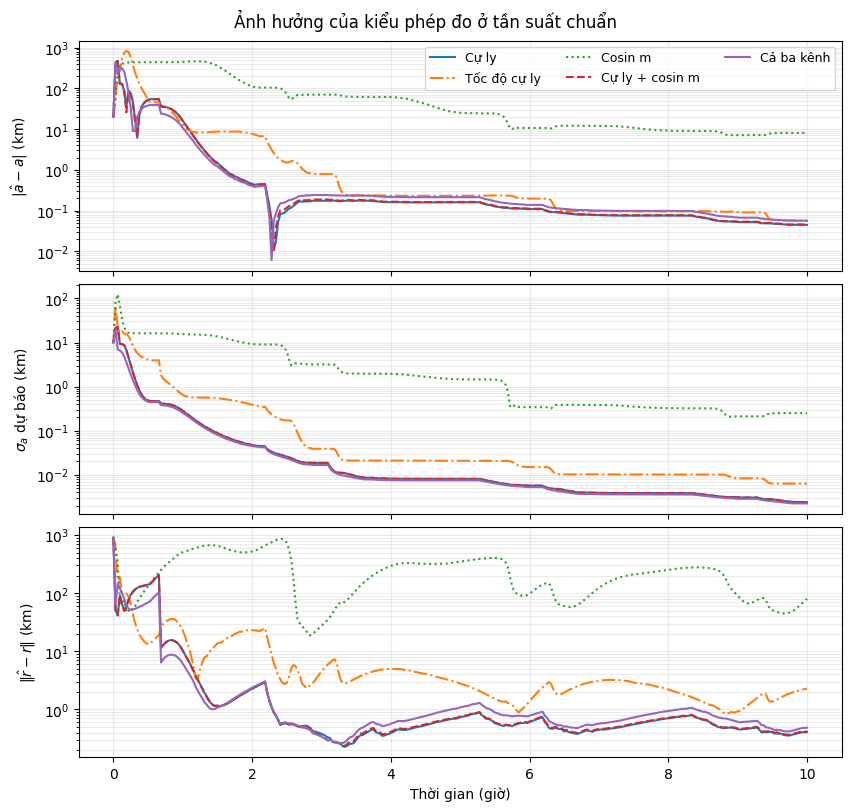

| Kiểu đo | RMS sai số $a$ (km) | RMS $\sigma_a$ (km) | RMS sai số vị trí (km) |
|---|---:|---:|---:|
| Cự ly | 0.06474 | 0.003419 | 0.5472 |
| Tốc độ cự ly | 0.08923 | 0.009233 | 2.132 |
| Cosin m | 9.167 | 0.3026 | 185.9 |
| Cự ly + cosin m | 0.066 | 0.003418 | 0.5597 |
| Cả ba kênh | 0.084 | 0.003185 | 0.7253 |

In [9]:
fig, axes = plt.subplots(
    3, 1, figsize=(8.4, 8), sharex=True, layout="constrained"
)
fig.suptitle("Ảnh hưởng của kiểu phép đo ở tần suất chuẩn")
styles = ("-", "-.", ":", "--", "-")
for (label, metrics), style in zip(type_metrics.items(), styles):
    for ax, metric in zip(axes, metrics):
        ax.semilogy(time_hours, metric, linestyle=style, label=label)

axes[0].set_ylabel(r"$|\hat a-a|$ (km)")
axes[1].set_ylabel(r"$\sigma_a$ dự báo (km)")
axes[2].set_ylabel(r"$\|\hat r-r\|$ (km)")
axes[2].set_xlabel("Thời gian (giờ)")
axes[0].legend(ncol=3, fontsize=9)
for ax in axes:
    ax.grid(alpha=0.25, which="both")
plt.show()

rows = [
    r"| Kiểu đo | RMS sai số $a$ (km) | RMS $\sigma_a$ (km) | "
    "RMS sai số vị trí (km) |",
    "|---|---:|---:|---:|",
]
for label, metrics in type_metrics.items():
    values = " | ".join(f"{rms(metric[last_orbit]):.4g}" for metric in metrics)
    rows.append(f"| {label} | {values} |")
display(Markdown("\n".join(rows)))

## G. Tần suất và số trạm

Dùng riêng cosin $m$ như Hình 8.6. Ba lịch thấp, chuẩn và cao dùng cùng
ba trạm để tách ảnh hưởng của tần suất. Lịch chuẩn với riêng trạm $1$
cho thấy ảnh hưởng của vùng phủ. Chỉ tiêu ở đây là sai số tương đối
của **độ lớn vị trí** $|\|\hat r\|-\|r\||/\|r\|$.

In [10]:
direction_channel = type_channels["Cosin m"]
frequency_results = {
    "Thấp (8 lần/giờ)": run_ekf(
        observations, state_prior, direction_channel,
        observations_per_hour["Thấp"],
    ),
    "Chuẩn (32 lần/giờ)": type_results["Cosin m"],
    "Cao (512 lần/giờ)": run_ekf(
        observations, state_prior, direction_channel,
        observations_per_hour["Cao"],
    ),
    "Chuẩn, 1 trạm": run_ekf(
        observations, state_prior, direction_channel, standard_rate,
        stations=(0,),
    ),
}
frequency_errors = {}
for label, (estimates, _, _) in frequency_results.items():
    radius_estimate = np.linalg.norm(estimates[:, :2], axis=1)
    relative_error = np.abs(radius_estimate - reference_radius)
    frequency_errors[label] = relative_error / reference_radius

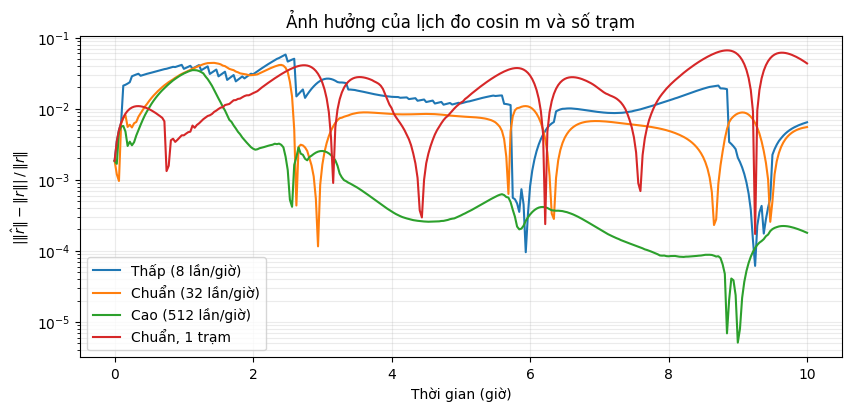

| Lịch đo | Số cặp mốc–trạm có dữ liệu | RMS tương đối, vòng cuối |
|---|---:|---:|
| Thấp (8 lần/giờ) | 71 | 1.125e-02 |
| Chuẩn (32 lần/giờ) | 279 | 5.246e-03 |
| Cao (512 lần/giờ) | 4473 | 1.344e-04 |
| Chuẩn, 1 trạm | 146 | 3.997e-02 |

In [11]:
_, ax = plt.subplots(figsize=(8.4, 4), layout="constrained")
for label, metric in frequency_errors.items():
    ax.semilogy(time_hours, metric, label=label)
ax.set(
    title="Ảnh hưởng của lịch đo cosin m và số trạm",
    xlabel="Thời gian (giờ)",
    ylabel=r"$|\|\hat r\|-\|r\||\,/\,\|r\|$",
)
ax.grid(alpha=0.25, which="both")
ax.legend()
plt.show()

rows = [
    "| Lịch đo | Số cặp mốc–trạm có dữ liệu | RMS tương đối, vòng cuối |",
    "|---|---:|---:|",
]
for label, metric in frequency_errors.items():
    count = frequency_results[label][2]
    rows.append(f"| {label} | {count} | {rms(metric[last_orbit]):.3e} |")
display(Markdown("\n".join(rows)))

Mỗi lần cập nhật bổ sung thông tin qua $H^\top R^{-1}H$ trong mô hình
tuyến tính hóa. Lịch dày cho thêm phép đo trong mỗi cửa sổ nhìn thấy
vệ tinh. Nhiều trạm tăng vùng phủ và thay đổi hướng quan sát, giúp
ràng buộc những thành phần trạng thái mà một trạm suy ra kém.

## H. Kiểm tra Monte Carlo

Dùng cấu hình cự ly với lịch chuẩn. Giữ chân trị và hình học cố định.
Trong mỗi lượt, lấy sai số tiên nghiệm Descartes độc lập từ
$\mathcal N(0,P_0)$ và sinh lại nhiễu đo. Với vị trí, so sánh
$\sqrt{\operatorname{mean}_j\|\hat r_j-r\|^2}$ với
$\sqrt{\operatorname{mean}_j\operatorname{tr}(P_{rr,j})}$.
Với bán trục lớn, so sánh RMSE theo lượt với
$\sqrt{\operatorname{mean}_j\sigma_{a,j}^2}$.

In [12]:
trial_count = 24
monte_carlo_rng = np.random.default_rng(817)
trial_priors = monte_carlo_rng.multivariate_normal(
    state_true_initial, initial_covariance, size=trial_count
)
trial_states = np.empty((trial_count, report_ticks.size, 4))
trial_covariances = np.empty((trial_count, report_ticks.size, 4, 4))

for trial, trial_prior in enumerate(trial_priors):
    trial_data = generate_observations(monte_carlo_rng)
    estimates, covariances, _ = run_ekf(
        trial_data, trial_prior, type_channels["Cự ly"], standard_rate
    )
    trial_states[trial] = estimates
    trial_covariances[trial] = covariances

trial_position_errors = np.linalg.norm(
    trial_states[..., :2] - reference_states[:, :2], axis=-1
)
position_rmse = rms(trial_position_errors, axis=0)
position_variances = np.trace(
    trial_covariances[..., :2, :2], axis1=-2, axis2=-1
)
position_predicted_rms = np.sqrt(np.mean(position_variances, axis=0))

axis_rmse = rms(semi_major_axis(trial_states) - reference_axis, axis=0)
axis_predicted_rms = rms(
    semi_major_axis_std(trial_states, trial_covariances), axis=0
)

Vị trí — tỷ số RMSE / RMS dự báo ở vòng cuối = 4.63
Bán trục lớn — tỷ số RMSE / RMS dự báo ở vòng cuối = 10.02


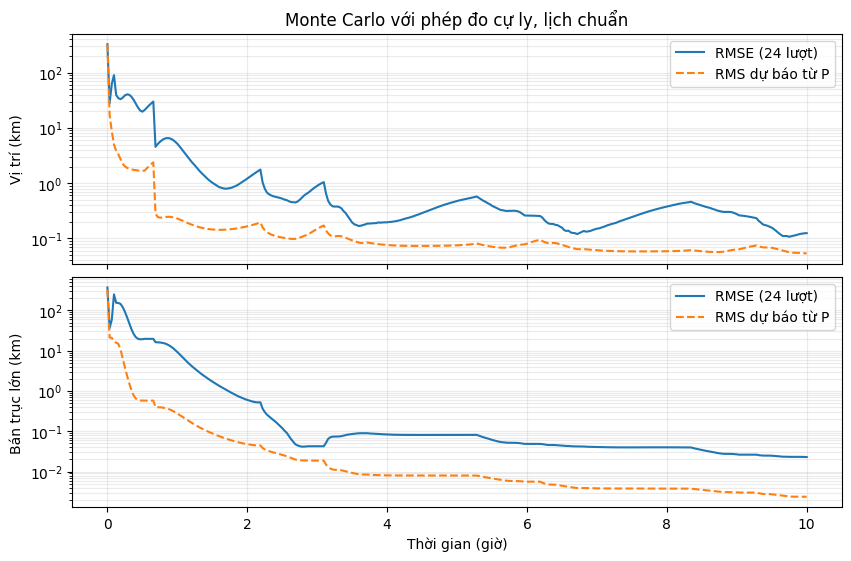

In [13]:
_, axes = plt.subplots(
    2, 1, figsize=(8.4, 5.5), sharex=True, layout="constrained"
)
metrics = (
    ("Vị trí", position_rmse, position_predicted_rms),
    ("Bán trục lớn", axis_rmse, axis_predicted_rms),
)
for ax, (label, empirical, predicted) in zip(axes, metrics):
    ax.semilogy(time_hours, empirical, label=f"RMSE ({trial_count} lượt)")
    ax.semilogy(time_hours, predicted, "--", label="RMS dự báo từ P")
    ax.set_ylabel(f"{label} (km)")
    ax.grid(alpha=0.25, which="both")
    ax.legend()
    ratio = rms(empirical[last_orbit]) / rms(predicted[last_orbit])
    print(f"{label} — tỷ số RMSE / RMS dự báo ở vòng cuối = {ratio:.2f}")

axes[0].set_title("Monte Carlo với phép đo cự ly, lịch chuẩn")
axes[1].set_xlabel("Thời gian (giờ)")
plt.show()

In [14]:
# Kiểm tra các ma trận P được ghi lại trong mọi cấu hình và lượt chạy.
scenario_covariances = [
    result[1]
    for result in (*type_results.values(), *frequency_results.values())
]
covariance_checks = np.concatenate([
    *scenario_covariances, trial_covariances.reshape(-1, 4, 4)
])
covariance_transposes = covariance_checks.swapaxes(-1, -2)
np.testing.assert_allclose(
    covariance_checks, covariance_transposes, rtol=1e-11, atol=1e-8
)
minimum_eigenvalue = np.linalg.eigvalsh(
    (covariance_checks + covariance_transposes) / 2
).min()
assert minimum_eigenvalue >= -1e-10
maximum_asymmetry = np.max(np.abs(covariance_checks - covariance_transposes))
print(f"Độ lệch đối xứng lớn nhất = {maximum_asymmetry:.2e}")
print(f"Trị riêng nhỏ nhất của P = {minimum_eigenvalue:.2e}")
print("P đối xứng và nửa xác định dương trong dung sai.")

Độ lệch đối xứng lớn nhất = 3.79e-10
Trị riêng nhỏ nhất của P = 7.63e-14
P đối xứng và nửa xác định dương trong dung sai.


## I. Kết luận

- **Kiểu đo.** Cự ly là kênh đơn hiệu quả nhất trong mô phỏng này,
  phù hợp xu hướng Hình 8.4–8.5. RMS sai số $a$ ở vòng cuối lần lượt
  khoảng $65$ m với cự ly, $89$ m với tốc độ cự ly và $9.17$ km với
  cosin $m$.
- **Kết hợp kênh.** Thêm cosin $m$ gần như giữ nguyên $\sigma_a$.
  Dùng cả ba kênh giảm RMS của $\sigma_a$ từ $3.42$ m xuống $3.19$ m.
  RMS sai số $a$ trong lần chạy này tăng từ $65$ m lên $84$ m.
  Hình 8.7 cũng cho thấy lợi ích hạn chế của cosin $m$ khi đã có cự ly.
- **Tần suất và vùng phủ.** Với ba trạm, tăng từ 8 lên 512 lần/giờ
  giảm RMS sai số tương đối của bán kính ở vòng cuối từ
  $1.13\times10^{-2}$ xuống $1.34\times10^{-4}$. Ở tần suất chuẩn,
  ba trạm cho RMS thấp hơn một trạm, cùng xu hướng với Hình 8.6.
- **Hiệu chuẩn.** Với 24 lượt đo cự ly, RMSE vòng cuối lớn gấp khoảng
  $4.63$ lần RMS dự báo cho vị trí và $10.02$ lần cho $a$. $P$ đối xứng
  và nửa xác định dương nhưng quá lạc quan cho cấu hình này. Một nguồn
  sai lệch có thể là tuyến tính hóa từ tiên nghiệm có bất định lớn.
- **Phạm vi.** Mức sai số phụ thuộc vào mô hình hai vật thể, hình học
  trạm và tiên nghiệm Descartes. Các mức khoảng $10$ m được mô tả
  trong sách và dao động của $a$ ở Hình 8.3 thuộc mô phỏng gốc.